# Âm thanh, thị trường và nhãn Hit trên Spotify

## Storytelling từ dữ liệu đã xử lý

Notebook này lần theo bốn câu hỏi: âm thanh trên bảng xếp hạng toàn cầu thay đổi thế nào theo tuần; đặc trưng âm nhạc ở các thị trường liên hệ ra sao với điểm hạnh phúc; xu hướng âm thanh diễn biến cùng thời gian COVID-19 như thế nào; và các bài được gắn nhãn Hit khác nhóm còn lại ra sao.

Các biểu đồ mô tả **những bài đã xuất hiện trên Spotify Charts**, không đại diện mọi bản phát hành hay toàn bộ người nghe. Các liên hệ quan sát được không chứng minh nguyên nhân. Định nghĩa Hit trong dữ liệu là `pop_score >= 50`, không phải Top 50.

## 1. Nạp dữ liệu và kiểm tra phạm vi

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from IPython.display import display

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial"]

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "data" / "processed").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Không tìm thấy data/processed từ thư mục hiện tại.")

DATA_DIR = PROJECT_ROOT / "data" / "processed"
weekly = pd.read_parquet(DATA_DIR / "mart_audio_trend_weekly.parquet")
country_year = pd.read_parquet(DATA_DIR / "mart_country_year.parquet")
ml_tracks = pd.read_parquet(DATA_DIR / "ml_tracks.parquet")
covid = pd.read_csv(DATA_DIR / "covid_weekly_clean.csv", parse_dates=["week"])

weekly["week"] = pd.to_datetime(weekly["week"])
print(f"Thư mục dữ liệu: {DATA_DIR}")
print(f"Mart tuần: {len(weekly):,} dòng | {weekly['chart_country'].nunique()} thị trường")
print(f"Mart quốc gia-năm: {len(country_year):,} dòng | {country_year['chart_country'].nunique()} quốc gia")
print(f"Tập bài hát: {len(ml_tracks):,} bài | Hit: {ml_tracks['is_hit'].mean():.2%}")
print(f"COVID tuần: {len(covid):,} dòng")

Thư mục dữ liệu: D:\ky1_nam3\Tương tác dữ liệu\project_ck\Spotify_Audio_Trends_Analytics\data\processed
Mart tuần: 5,548 dòng | 74 thị trường
Mart quốc gia-năm: 141 dòng | 73 quốc gia
Tập bài hát: 39,190 bài | Hit: 13.94%
COVID tuần: 12,136 dòng


## 2. Âm thanh trên bảng xếp hạng toàn cầu biến đổi theo thời gian

**Câu hỏi:** Mức valence và energy trung bình của các vị trí trên bảng Global thay đổi thế nào từ cuối 2016 đến 2022?

Mỗi điểm là trung bình không trọng số của các bài trong bảng Global của tuần đó; đường làm mượt dùng cửa sổ 13 tuần. Vì vậy, biểu đồ mô tả thành phần âm thanh của bảng xếp hạng, không phải tâm trạng của mọi người nghe.

2016: chỉ có 1 tuần (2016-12-29 đến 2016-12-29); không so tổng streams năm này trực tiếp với năm đủ kỳ.
2022: chỉ có 28 tuần (2022-01-06 đến 2022-07-14); không so tổng streams năm này trực tiếp với năm đủ kỳ.


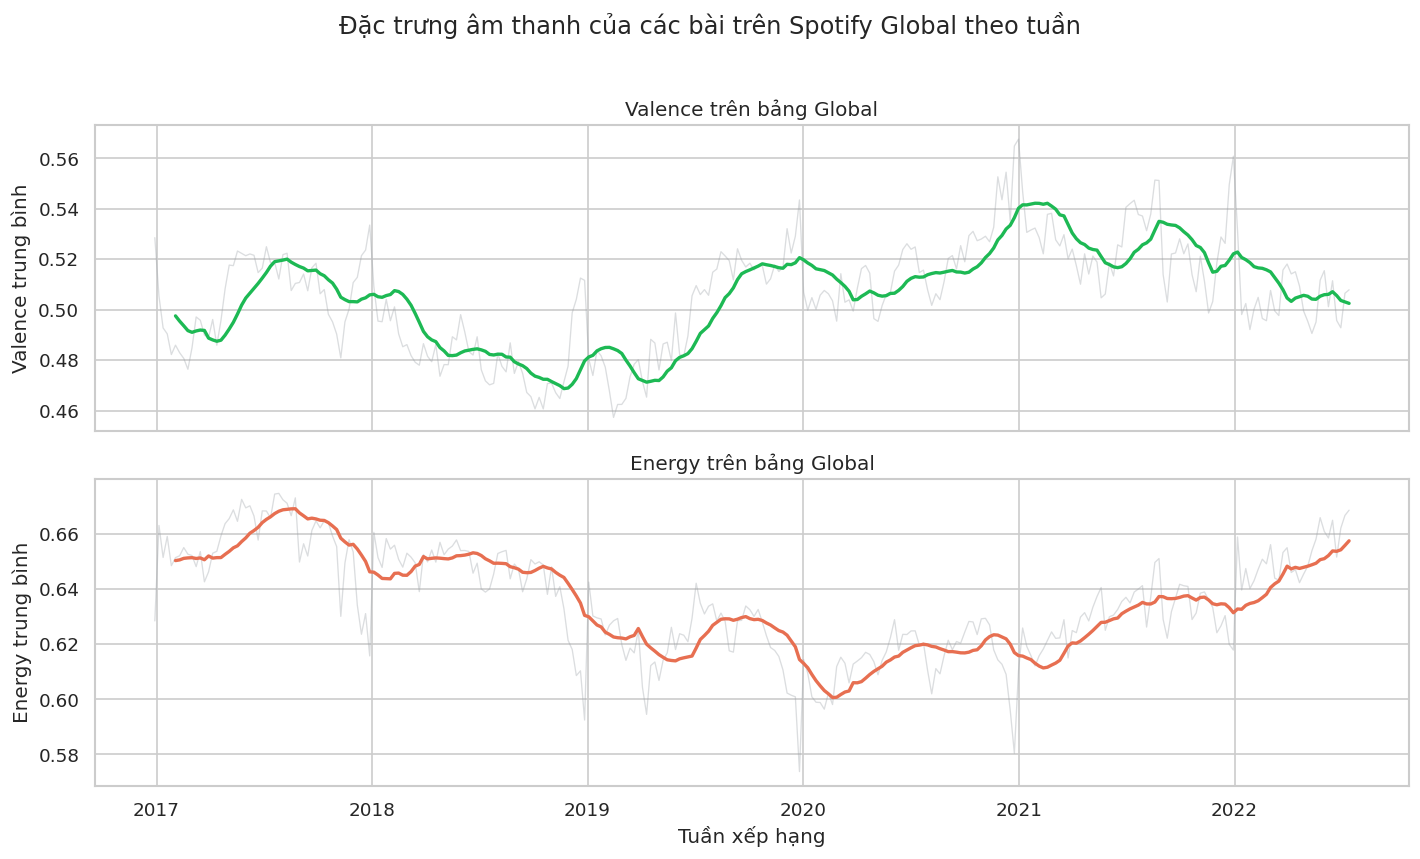

,year,weeks,valence_mean,energy_mean,streams,first_week,last_week
0,2016,1,0.529,0.628,1.184878e+09,2016-12-29,2016-12-29
1,2017,52,0.506,0.657,7.650618e+10,2017-01-05,2017-12-28
2,2018,52,0.483,0.645,8.446579e+10,2018-01-04,2018-12-27
3,2019,52,0.498,0.621,8.999227e+10,2019-01-03,2019-12-26
4,2020,53,0.518,0.614,9.661267e+10,2020-01-02,2020-12-31
5,2021,52,0.526,0.630,9.831570e+10,2021-01-07,2021-12-30
6,2022,28,0.504,0.652,5.266716e+10,2022-01-06,2022-07-14


In [2]:
global_weekly = (
    weekly.loc[weekly["chart_country"].eq("Global")]
    .sort_values("week")
    .copy()
)
if global_weekly.empty:
    raise ValueError("Mart tuần không có dòng chart_country='Global'.")

global_weekly["valence_13w"] = global_weekly["valence_mean"].rolling(13, min_periods=6).mean()
global_weekly["energy_13w"] = global_weekly["energy_mean"].rolling(13, min_periods=6).mean()
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(global_weekly["week"], global_weekly["valence_mean"], color="#9aa0a6", alpha=.35, lw=.8)
axes[0].plot(global_weekly["week"], global_weekly["valence_13w"], color="#1DB954", lw=2)
axes[0].set_ylabel("Valence trung bình")
axes[0].set_title("Valence trên bảng Global")
axes[1].plot(global_weekly["week"], global_weekly["energy_mean"], color="#9aa0a6", alpha=.35, lw=.8)
axes[1].plot(global_weekly["week"], global_weekly["energy_13w"], color="#e76f51", lw=2)
axes[1].set_ylabel("Energy trung bình")
axes[1].set_title("Energy trên bảng Global")
axes[1].set_xlabel("Tuần xếp hạng")
fig.suptitle("Đặc trưng âm thanh của các bài trên Spotify Global theo tuần", y=1.02)
fig.tight_layout()
plt.show()

global_year = (global_weekly.assign(year=global_weekly["week"].dt.year)
               .groupby("year", as_index=False)
               .agg(weeks=("week", "nunique"),
                    valence_mean=("valence_mean", "mean"),
                    energy_mean=("energy_mean", "mean"),
                    streams=("total_streams", "sum"),
                    first_week=("week", "min"),
                    last_week=("week", "max")))
display(global_year.round(3))
partial_years = global_year[global_year["weeks"] < 50]
for row in partial_years.itertuples(index=False):
    print(f"{row.year}: chỉ có {row.weeks} tuần ({row.first_week:%Y-%m-%d} đến {row.last_week:%Y-%m-%d}); không so tổng streams năm này trực tiếp với năm đủ kỳ.")

**Insight và phạm vi:** Bảng theo năm cho thấy valence trung bình thấp nhất vào 2018 (0.483) rồi cao hơn trong 2020–2021 (0.518–0.526), trước khi giảm ở phần dữ liệu 2022 (0.504). Tuy nhiên, 2016 chỉ có 1 tuần và 2022 có 28 tuần đến 14/07; các năm này chưa đủ kỳ, nên không so sánh tổng streams hoặc coi trung bình năm là đại diện đủ năm. Xu hướng chỉ mô tả thành phần âm thanh của chart, không giải thích nguyên nhân.

## 3. Điểm hạnh phúc quốc gia và âm thanh được nghe nhiều

**Câu hỏi:** Ở các thị trường có dữ liệu trong 2021–2022, điểm hạnh phúc liên hệ thế nào với valence của các bài trong bảng xếp hạng?

`valence_weighted` là trung bình valence có trọng số streams trong mart quốc gia-năm. Phân tích dùng `happiness_score` của World Happiness Report, không dùng `gdp_factor` như một phép đo GDP. Mỗi năm được tính riêng; hai năm của cùng quốc gia không phải hai quan sát hoàn toàn độc lập.

2021: Spearman rho=0.0002, p=0.9988. Chưa thấy bằng chứng thống kê về liên hệ đơn điệu trong mẫu này.
2022: Spearman rho=0.0643, p=0.5889. Chưa thấy bằng chứng thống kê về liên hệ đơn điệu trong mẫu này.


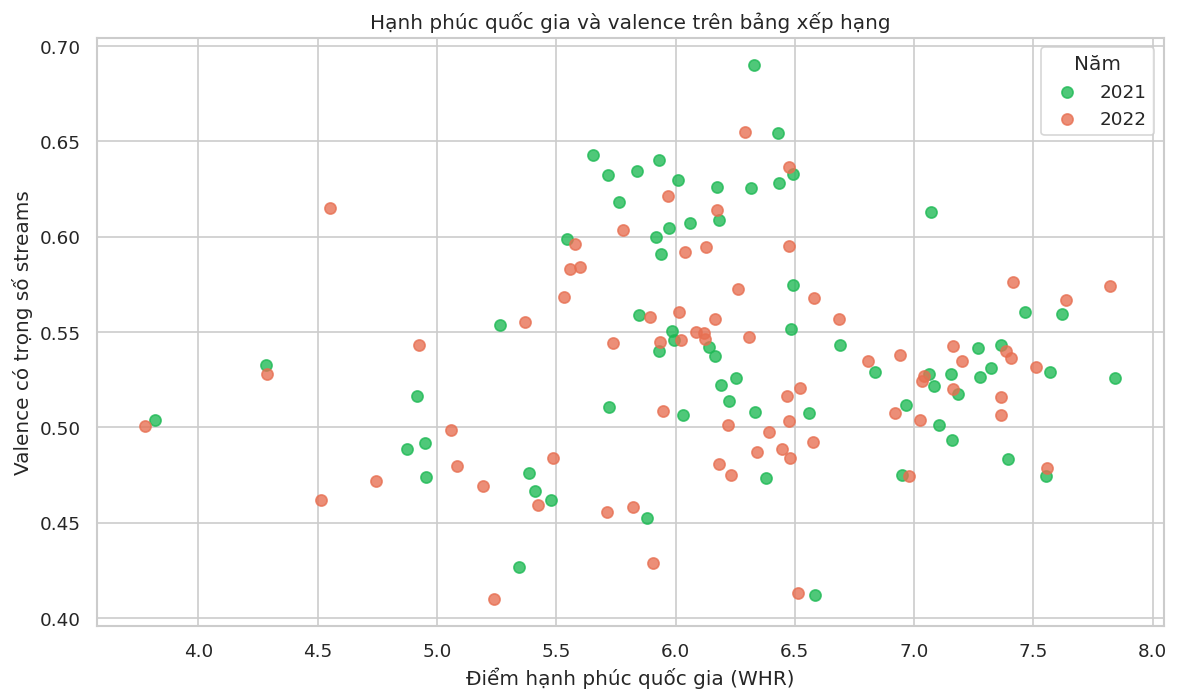

,Năm,Số quốc gia,Spearman rho,p-value
0,2021,68,0.0002,0.9988
1,2022,73,0.0643,0.5889


In [3]:
required = {"year", "chart_country", "happiness_score", "valence_weighted", "wb_region"}
missing = required - set(country_year.columns)
if missing:
    raise KeyError(f"Thiếu cột trong mart_country_year: {sorted(missing)}")

cy = country_year.dropna(subset=["happiness_score", "valence_weighted"]).copy()
fig, ax = plt.subplots(figsize=(10, 6))
palette = {2021: "#1DB954", 2022: "#e76f51"}
for year, group in cy.groupby("year"):
    ax.scatter(group["happiness_score"], group["valence_weighted"],
               s=45, alpha=.78, color=palette.get(year, "#5470c6"), label=str(year))
ax.set_xlabel("Điểm hạnh phúc quốc gia (WHR)")
ax.set_ylabel("Valence có trọng số streams")
ax.set_title("Hạnh phúc quốc gia và valence trên bảng xếp hạng")
ax.legend(title="Năm")
fig.tight_layout()
plt.show()

correlation_rows = []
for year, group in cy.groupby("year"):
    rho, p_value = spearmanr(group["happiness_score"], group["valence_weighted"])
    correlation_rows.append({"Năm": int(year), "Số quốc gia": len(group),
                             "Spearman rho": rho, "p-value": p_value})
correlation = pd.DataFrame(correlation_rows)
display(correlation.round(4))
for _, row in correlation.iterrows():
    print(f"{int(row['Năm'])}: Spearman rho={row['Spearman rho']:.4f}, p={row['p-value']:.4f}. " +
          ("Chưa thấy bằng chứng thống kê về liên hệ đơn điệu trong mẫu này." if row['p-value'] >= 0.05 else "Có dấu hiệu liên hệ đơn điệu trong mẫu; không suy ra quan hệ nhân quả."))

**Cách diễn giải:** Dấu và độ lớn Spearman mô tả chiều/mức liên hệ đơn điệu trong mẫu quốc gia từng năm. p-value không chứng minh quan hệ nhân quả; số quốc gia mỗi năm còn hạn chế. Không gọi đây là “nghịch lý GDP”, vì phép phân tích này không dùng GDP.

## 4. Xu hướng âm thanh trong cùng giai đoạn COVID-19

**Câu hỏi:** Valence trên Spotify Global biến động ra sao trong những tuần có dữ liệu tử vong COVID toàn cầu?

Ghép theo tuần với dòng `Global` trong `covid_weekly_clean.csv`, chỉ giữ phần thời gian hai nguồn cùng có dữ liệu. Hai ô biểu đồ dùng đơn vị riêng để tránh so sánh trực tiếp quy mô valence và số ca tử vong. Báo cáo số tuần ghép được để thấy phạm vi thực tế.

Số tuần ghép được: 130
Khoảng thời gian: 2020-01-23 đến 2022-07-14
Giá trị weekly_deaths âm trong giai đoạn ghép: 0 tuần
Valence trung bình 13 tuần đầu/cuối: 0.506 / 0.503.
Đỉnh trung bình tử vong 4 tuần: 2021-02-04 (98,313 ca/tuần); valence tại tuần đó=0.531.


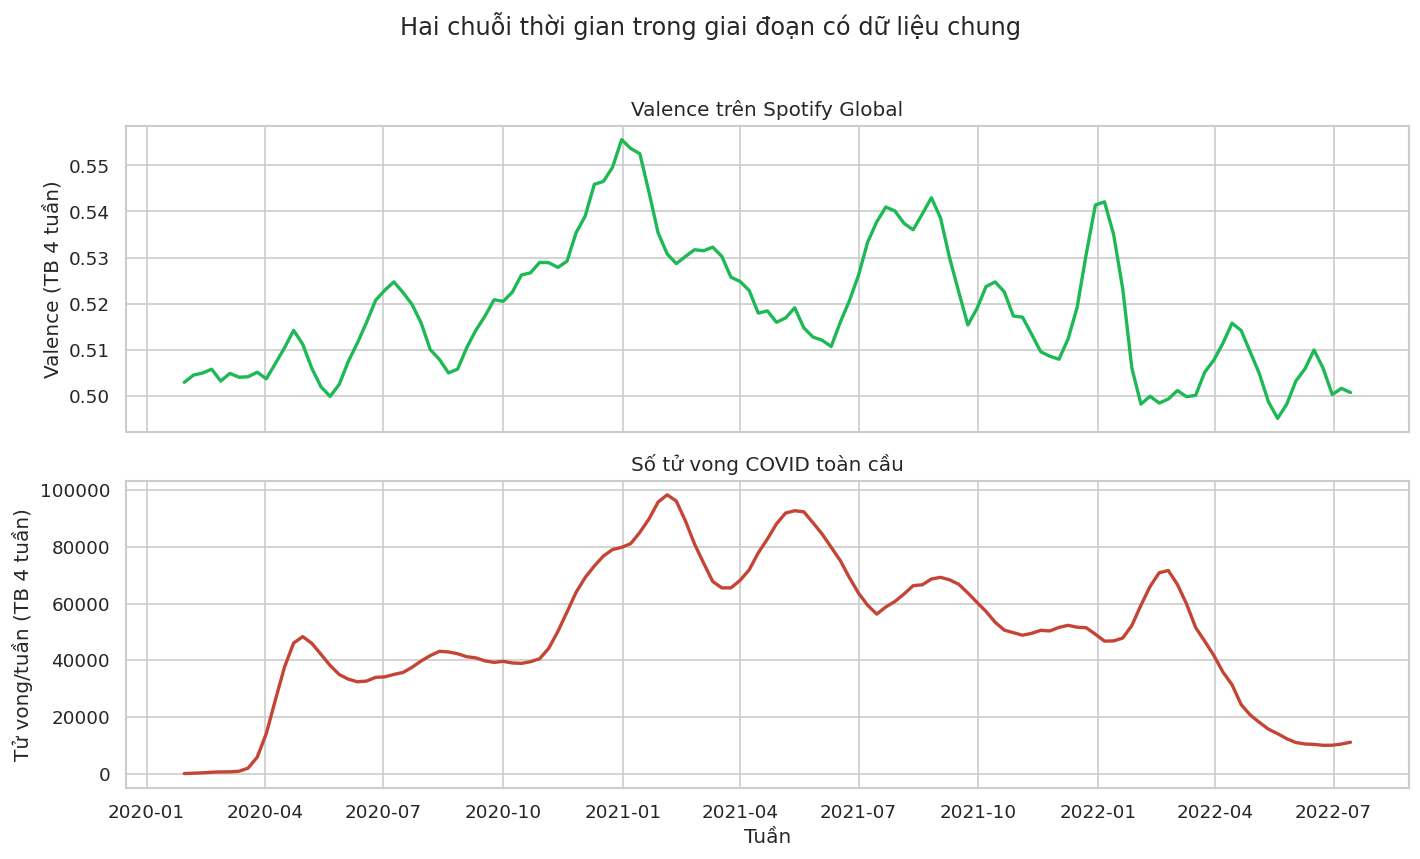

In [4]:
covid_global = covid.loc[covid["country"].astype(str).str.casefold().eq("global"),
                         ["week", "weekly_deaths"]].copy()
covid_global["week"] = pd.to_datetime(covid_global["week"])
global_covid = global_weekly[["week", "valence_mean", "energy_mean"]].merge(
    covid_global, on="week", how="inner", validate="one_to_one"
).sort_values("week")
if global_covid.empty:
    raise ValueError("Không có tuần giao nhau giữa mart Global và chuỗi COVID Global.")

global_covid["valence_4w"] = global_covid["valence_mean"].rolling(4, min_periods=2).mean()
global_covid["deaths_4w"] = global_covid["weekly_deaths"].rolling(4, min_periods=2).mean()
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(global_covid["week"], global_covid["valence_4w"], color="#1DB954", lw=2)
axes[0].set_ylabel("Valence (TB 4 tuần)")
axes[0].set_title("Valence trên Spotify Global")
axes[1].plot(global_covid["week"], global_covid["deaths_4w"], color="#c44536", lw=2)
axes[1].set_ylabel("Tử vong/tuần (TB 4 tuần)")
axes[1].set_title("Số tử vong COVID toàn cầu")
axes[1].set_xlabel("Tuần")
fig.suptitle("Hai chuỗi thời gian trong giai đoạn có dữ liệu chung", y=1.02)
fig.tight_layout()
plt.show()

print(f"Số tuần ghép được: {len(global_covid):,}")
print(f"Khoảng thời gian: {global_covid['week'].min():%Y-%m-%d} đến {global_covid['week'].max():%Y-%m-%d}")
print(f"Giá trị weekly_deaths âm trong giai đoạn ghép: {(global_covid['weekly_deaths'] < 0).sum():,} tuần")
start_13 = global_covid.head(13)
end_13 = global_covid.tail(13)
peak = global_covid.loc[global_covid['deaths_4w'].idxmax()]
print(f"Valence trung bình 13 tuần đầu/cuối: {start_13['valence_mean'].mean():.3f} / {end_13['valence_mean'].mean():.3f}.")
print(f"Đỉnh trung bình tử vong 4 tuần: {peak['week']:%Y-%m-%d} ({peak['deaths_4w']:,.0f} ca/tuần); valence tại tuần đó={peak['valence_4w']:.3f}.")

**Quan sát và giới hạn:** Valence trung bình của 13 tuần đầu và cuối lần lượt là 0.506 và 0.503, khá ổn định ở hai đầu giai đoạn. Tại đỉnh tử vong trung bình 4 tuần ngày 04/02/2021, valence là 0.531. Đây là hai chuỗi cùng thời gian, không chứng minh COVID làm thay đổi âm nhạc hay cho biết tác động trễ. Phân tích ghép được 130 tuần từ 23/01/2020 đến 14/07/2022; không có giá trị tử vong tuần âm trong phần ghép này.

## 5. Đặc trưng âm học và nhãn Hit trong mẫu bài đã lên bảng

**Câu hỏi:** Một số đặc trưng âm thanh có phân bố khác nhau giữa nhóm `is_hit = 1` và `is_hit = 0` không?

Nhãn Hit là `pop_score >= 50`; mỗi bài chỉ xuất hiện một lần trong `ml_tracks`. Boxplot ẩn dấu chấm ngoại lệ để dễ so sánh, nhưng không loại các bài đó khỏi dữ liệu hay bảng thống kê. Biểu đồ mô tả phân bố, không khẳng định đặc trưng nào tạo ra thành công. Mẫu chỉ gồm track từng vào bảng xếp hạng.

Hit: 5,463/39,190 bài (13.94%)
Chênh trung vị Hit - Non-Hit: loudness +0.460 dB; speechiness -0.013; duration +0.124 phút (+7.5 giây); energy +0.004.


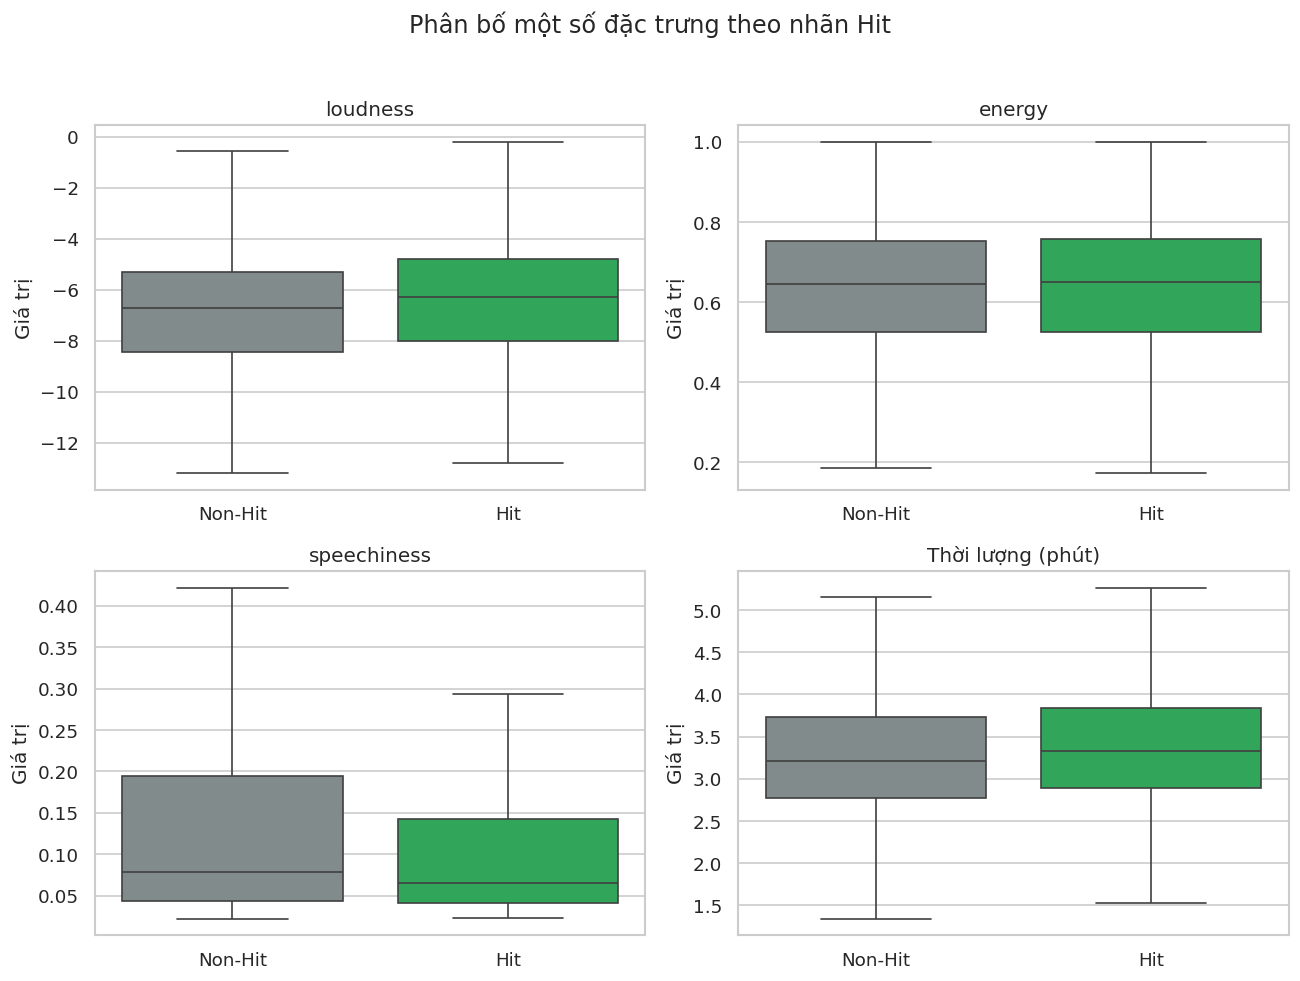

loudness        energy        speechiness        duration_min       
          median   mean median   mean      median   mean       median   mean
is_hit                                                                      
Non-Hit   -6.731 -7.093  0.645  0.633       0.078  0.134        3.208  3.324
Hit       -6.271 -6.612  0.649  0.633       0.065  0.110        3.332  3.443

In [5]:
if "is_hit" not in ml_tracks or "pop_score" not in ml_tracks:
    raise KeyError("ml_tracks cần có is_hit và pop_score.")
if not ml_tracks["is_hit"].eq(ml_tracks["pop_score"].ge(50).astype(int)).all():
    raise ValueError("Nhãn is_hit không khớp định nghĩa pop_score >= 50.")

ml_tracks["duration_min"] = ml_tracks["duration"] / 60000
hit_features = ["loudness", "energy", "speechiness", "duration_min"]
missing = set(hit_features) - set(ml_tracks.columns)
if missing:
    raise KeyError(f"Thiếu đặc trưng âm học: {sorted(missing)}")
plot_data = ml_tracks[hit_features + ["is_hit"]].melt(
    id_vars="is_hit", var_name="Đặc trưng", value_name="Giá trị")
plot_data["Nhãn"] = plot_data["is_hit"].map({0: "Non-Hit", 1: "Hit"})
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, feature in zip(axes.flat, hit_features):
    sns.boxplot(data=plot_data[plot_data["Đặc trưng"].eq(feature)],
                x="Nhãn", y="Giá trị", hue="Nhãn", legend=False,
                order=["Non-Hit", "Hit"], showfliers=False, ax=ax,
                palette={"Non-Hit": "#7f8c8d", "Hit": "#1DB954"})
    ax.set_title("Thời lượng (phút)" if feature == "duration_min" else feature)
    ax.set_xlabel("")
fig.suptitle("Phân bố một số đặc trưng theo nhãn Hit", y=1.02)
fig.tight_layout()
plt.show()

hit_summary = ml_tracks.groupby("is_hit")[hit_features].agg(["median", "mean"])
hit_summary.index = hit_summary.index.map({0: "Non-Hit", 1: "Hit"})
display(hit_summary.round(3))
print(f"Hit: {int(ml_tracks['is_hit'].sum()):,}/{len(ml_tracks):,} bài ({ml_tracks['is_hit'].mean():.2%})")
medians = ml_tracks.groupby("is_hit")[hit_features].median()
delta = medians.loc[1] - medians.loc[0]
print(f"Chênh trung vị Hit - Non-Hit: loudness {delta['loudness']:+.3f} dB; speechiness {delta['speechiness']:+.3f}; duration {delta['duration_min']:+.3f} phút ({delta['duration_min'] * 60:+.1f} giây); energy {delta['energy']:+.3f}.")

Trong mẫu này, nhóm Hit có trung vị loudness cao hơn khoảng 0.46 dB, speechiness thấp hơn 0.013 và thời lượng dài hơn khoảng 7.5 giây; trung vị energy gần như không đổi (chênh 0.004). Đây là khác biệt mô tả giữa các bài đã lên bảng. Chúng không phải ngưỡng sản xuất tối ưu hay công thức tạo Hit; các đặc trưng có thể liên hệ với nhau và nhãn Hit được tạo từ thành tích trên bảng.

### Kết quả mô hình Logistic Regression từ `03_model.ipynb`

Đoạn dưới đọc các metric đã lưu trong `models/model_metrics.json`. Đây là cùng thí nghiệm phân loại nhãn Hit, không phải kiểm chứng hiệu năng ngoài tập dữ liệu.

In [6]:
metrics_path = PROJECT_ROOT / "models" / "model_metrics.json"
if metrics_path.exists():
    with metrics_path.open(encoding="utf-8") as f:
        model_results = json.load(f)
    metrics = model_results.get("metrics", {})
    metric_rows = [
        ("Precision", metrics.get("precision")),
        ("Recall", metrics.get("recall")),
        ("F1", metrics.get("f1_score")),
        ("Accuracy", metrics.get("accuracy")),
        ("ROC-AUC", metrics.get("roc_auc")),
    ]
    model_table = pd.DataFrame(metric_rows, columns=["Chỉ số", "Giá trị"])
    model_table["Giá trị"] = model_table["Giá trị"].map(
        lambda x: f"{x:.4f}" if pd.notna(x) else "Không có")
    display(model_table)
    cm = np.asarray(metrics.get("confusion_matrix", []))
    if cm.shape == (2, 2):
        tn, fp, fn, tp = cm.ravel()
        print(f"Confusion matrix [[TN, FP], [FN, TP]] = {cm.tolist()}")
        print(f"Trong {tp + fp:,} bài được dự đoán Hit, đúng {tp:,}; precision = {tp/(tp+fp):.2%}.")
else:
    print(f"Chưa có {metrics_path}. Chạy và lưu kết quả mô hình ở 03_model.ipynb để hiển thị metric.")

Confusion matrix [[TN, FP], [FN, TP]] = [[3669, 3076], [436, 657]]
Trong 3,733 bài được dự đoán Hit, đúng 657; precision = 17.60%.


,Chỉ số,Giá trị
0,Precision,0.1760
1,Recall,0.6011
2,F1,0.2723
3,Accuracy,0.5519
4,ROC-AUC,0.5906


**Thông điệp:** Mô hình có khả năng phân biệt Hit còn hạn chế; Recall và Precision kể hai khía cạnh khác nhau, và phần lớn dự đoán Hit ở ngưỡng đang báo cáo vẫn là nhầm. Hãy trình bày nó như một khảo sát tín hiệu từ đặc trưng âm học, không phải công cụ quyết định đầu tư hay cam kết thành công.

## 6. Kết luận câu chuyện

1. Bảng Global có thể được theo dõi theo tuần để thấy thay đổi trong valence và energy của các bài đang thịnh hành.
2. Mart quốc gia-năm cho phép khảo sát liên hệ giữa valence được streams-weight và điểm hạnh phúc trong 2021–2022; không thể suy thành quan hệ nhân quả hay kết luận về GDP.
3. Chuỗi âm thanh và COVID có giai đoạn quan sát chung, nhưng trùng biến động theo thời gian không chứng minh đại dịch làm đổi gu nghe nhạc.
4. Nhãn Hit phản ánh điểm tổng hợp thành tích chart. Đặc trưng âm học có liên hệ quan sát được, song kết quả mô hình trên tập hiện tại còn yếu và mẫu không bao gồm bài chưa từng lên bảng.

### Nguồn dữ liệu

- `data/processed/mart_audio_trend_weekly.parquet`: đặc trưng âm thanh theo thị trường-tuần.
- `data/processed/mart_country_year.parquet`: đặc trưng âm thanh và chỉ số WHR theo quốc gia-năm.
- `data/processed/covid_weekly_clean.csv`: tử vong COVID theo quốc gia-tuần.
- `data/processed/ml_tracks.parquet`: một dòng mỗi bài cùng `pop_score` và `is_hit`.
- `models/model_metrics.json`: metric đã lưu từ thí nghiệm trong `03_model.ipynb`.